In [63]:
import os

os.chdir(r"C:\Users\loren\Documents\Tortues\Martinique_Verte")

print(os.getcwd())

C:\Users\loren\Documents\Tortues\Martinique_Verte


In [64]:

from os import listdir
import datetime
import numpy as np    
import matplotlib.pyplot as plt
import pandas as pd

In [65]:
PATH_Pred=r"C:\Users\loren\Documents\Tortues\Martinique_Verte\Preds_Bea_semi_supervised\Preds\C0"

In [66]:
def plot_categorical_vector(ax, vector, class_nb, class_names,
                            markersize=2, color=None, label=None, alpha=1):
    if color==None :
        color = ['darkred', 'darkgray', 'chartreuse', 'gold','darkorange','deeppink','navy']
       
    
    for cat in range(class_nb):
        ax.set_label("toto")
        here=(vector==cat)
        x_here=np.arange(len(vector))[here]
        y_here=cat*np.ones(len(vector))[here]
        line,=ax.plot(x_here, y_here,'o',markersize=markersize,color=color[cat], alpha=alpha)

    line.set_label(label)   

    ax.set_yticks(range(class_nb))
    ax.tick_params(colors='coral')

    # replacing labels to class names
    labels=[]
    for cat in range(len(class_names)):        
        labels.append(str(cat)+":"+class_names[cat])
    ax.set_yticklabels(labels)
    
#histogramme
def plot_histogramme(Y_stick_pred,TV):
    counts = {}
    for i in range(len(CLASSES)):
        here=Y_stick_pred==i
        counts[i]=np.arange(len(Y_stick_pred))[here].shape[0]
        counts
    plt.clf()
    plt.style.use('seaborn-dark')
    plt.title("Behaviors distribution", fontsize = 16)
    ytics=range(len(CLASSES))
    ytics_label=[CLASS for CLASS in CLASSES]
    plt.xticks(ytics,ytics_label);
    plt.bar(counts.keys(), counts.values(), width=0.95, edgecolor='k');
    plt.savefig(PATH_Pred+"/"+TV+"_behaviour_frequence")
    
def plot_histogramme(Y_stick_pred,TV):
    counts = {}
    for i in range(len(CLASSES)):
        here=Y_stick_pred==i
        counts[i]=np.arange(len(Y_stick_pred))[here].shape[0]
        counts
    
    fig2, ax2 = plt.subplots(figsize=(9, 9))
    
    ax2.set_title("Behaviors distribution", fontsize = 16)
    ytics=range(len(CLASSES))
    ytics_label=[CLASS for CLASS in CLASSES]
    ax2.set_xticks(ytics)
    ax2.set_xticklabels(ytics_label)
    ax2.bar(counts.keys(), counts.values(), width=0.95, edgecolor='k');
    fig2.savefig(PATH_Pred+"/"+TV+"_behaviour_frequence")


#budget time
def plot_budget_time(Y_stick_pred,TV):
    unique_pred, counts_pred = np.unique(Y_stick_pred, return_counts=True)

    counts=np.zeros(7,dtype=int)
    for x in unique_pred:
        idx=int(np.where(unique_pred==x)[0][0])
        counts[x] = counts_pred[idx]

    colors = ['darkred', 'darkgray', 'chartreuse', 'gold','darkorange','deeppink','navy']
    labels = ['Autre','Respiration','Alimentation','Nage inactive','Repos','Se gratte','Nage active']
    sizes = [(counts/np.sum(counts))*100]
#patches, texts = plt.pie(sizes, colors=colors, shadow=True, autopct='%1.1f%%',startangle=90)
    fig1, ax1 = plt.subplots(figsize=(9, 9))
    fig1.subplots_adjust(0,0,1,1)
    ax1.pie(sizes[0], labels=labels, colors=colors, 
        autopct='%1.1f%%', shadow=True, startangle=90)
#patches, texts = ax1.pie(sizes, colors=colors, shadow=False, startangle=90)
#plt.legend(patches, labels, loc="upper right", bbox_to_anchor=(1.4, 0.8),fontsize=24)
    ax1.axis('equal')
#ax1.title('Budget Time Predicted', color="coral", fontsize=16)
    #fig1.show()
    fig1.savefig(PATH_Pred+"/"+TV+"_behaviour_piechart")

#plot according to time
def plot_beh_accroding_time(Y_stick_spred, df,TV,start=0, end=-1):
    nb=6
    fig,axs=plt.subplots(nb,1,figsize=(20,12*nb),sharex=False)
    axs[0].set_title("Tortue Verte Martinique", color="coral", fontsize=20)

    y_pred=Y_stick_pred[start:end]
    plot_categorical_vector(ax=axs[0], vector=y_pred, class_nb=7, class_names=CLASSES)
    axs[1].plot(df[start:end,6])
    axs[2].plot(df[start:end,0])
    axs[3].plot(df[start:end,3])
    axs[4].plot(df[start:end,4])
    axs[5].plot(df[start:end,5])
    
    fig.savefig(PATH_Pred+"/"+TV+"_behaviour_time.png")

In [67]:
def creating_rblt_fichier(Y_stick_pred,TV,nb,time_interval,date_start):
    behav=Y_stick_pred.copy()

    states=np.diff(behav)!=0
    fin=np.append(np.where(states)[0],behav.shape[0]-1)
    start=np.insert(np.where(states)[0], 0, 0)


    behaviour=[]
    for i in range(len(behav)):
        behaviour.append(CLASSES[behav[i]])
    
    df = pd.DataFrame({'Behaviour_ind': Y_stick_pred, 'Behaviour': behaviour})

    Date_depart=datetime.datetime.strptime(time_interval[0],"%Y-%m-%d %H:%M:%S")
    Date_depart
    dt_ref=Date_depart
    time=[]
    for i in range(len(Y_stick_pred)):
        time.append(dt_ref)
        dt_ref += datetime.timedelta(milliseconds=50)
    df['datetime']=pd.to_datetime(time,format='%Y.%m.%d %H:%M:%S.%f')

    rblt = pd.DataFrame({'Behaviour_ind': [df.iloc[x,0] for x in fin], 'Behavior': [df.iloc[x,1] for x in fin], 'datetime_deb':[df.iloc[x,2] for x in start],'datetime_fin':[df.iloc[x,2] for x in fin]})
    deb_s=[(rblt.iloc[x,2]-date_start).total_seconds() for x in range(rblt.shape[0])]
    fin_s=[(rblt.iloc[x,3]-date_start).total_seconds() for x in range(rblt.shape[0])]
    rblt['Start (s)']=deb_s
    rblt['Stop (s)']=fin_s
    rblt['Duration (s)']=[fin_s[x]-deb_s[x] for x in range(len(deb_s))]
    
    rblt.to_csv(PATH_Pred+"/"+TV+"_behaviours_rblt.csv",sep=';',index=False)
    div=rblt.shape[0]//nb
    rblt_cut=rblt.iloc[0:div,:].copy()
    rblt_cut.to_csv(PATH_Pred+"/"+TV+"_behaviours_d0_rblt.csv",sep=';',index=False)

    for i in range(1,nb):
        w=div*i
        v=div*(i+1)
        rblt_cut=rblt.iloc[w:v,:].copy()
        rblt_cut.to_csv(PATH_Pred+"/"+TV+"_behaviours_d"+str(i)+"_rblt.csv",sep=';',index=False)



In [68]:
CLASSES=['Other','Breathing','Feeding','Gliding','Resting','Scratching','Swimming']

In [69]:
ALL_TV=["AGM1_TV_GA_23122020",
        "AGM1_TV_GA_25052021",
        "AGM4_TV_GA_30042021"]

AGM1_TV_GA_23122020
AGM1_TV_GA_25052021
AGM4_TV_GA_30042021


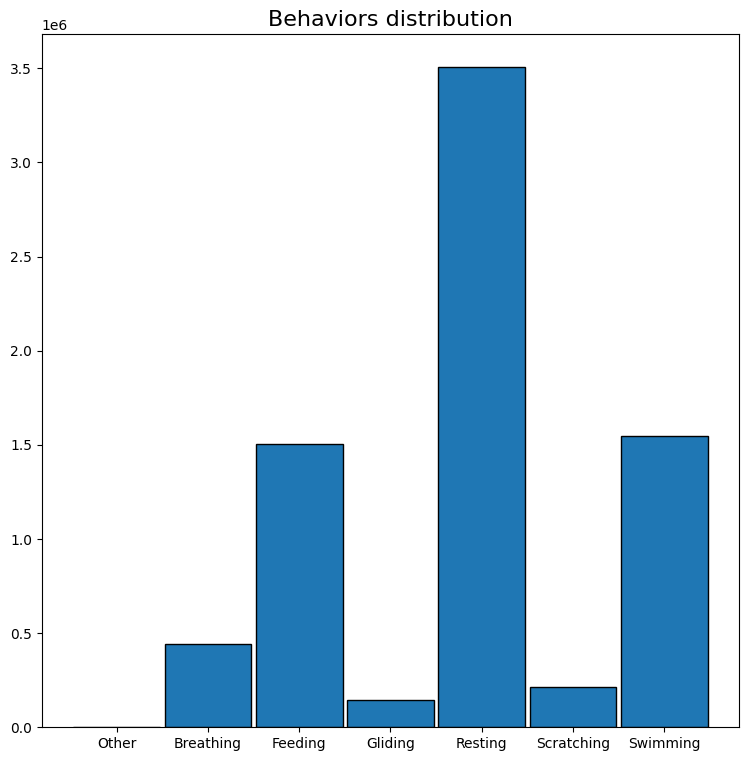

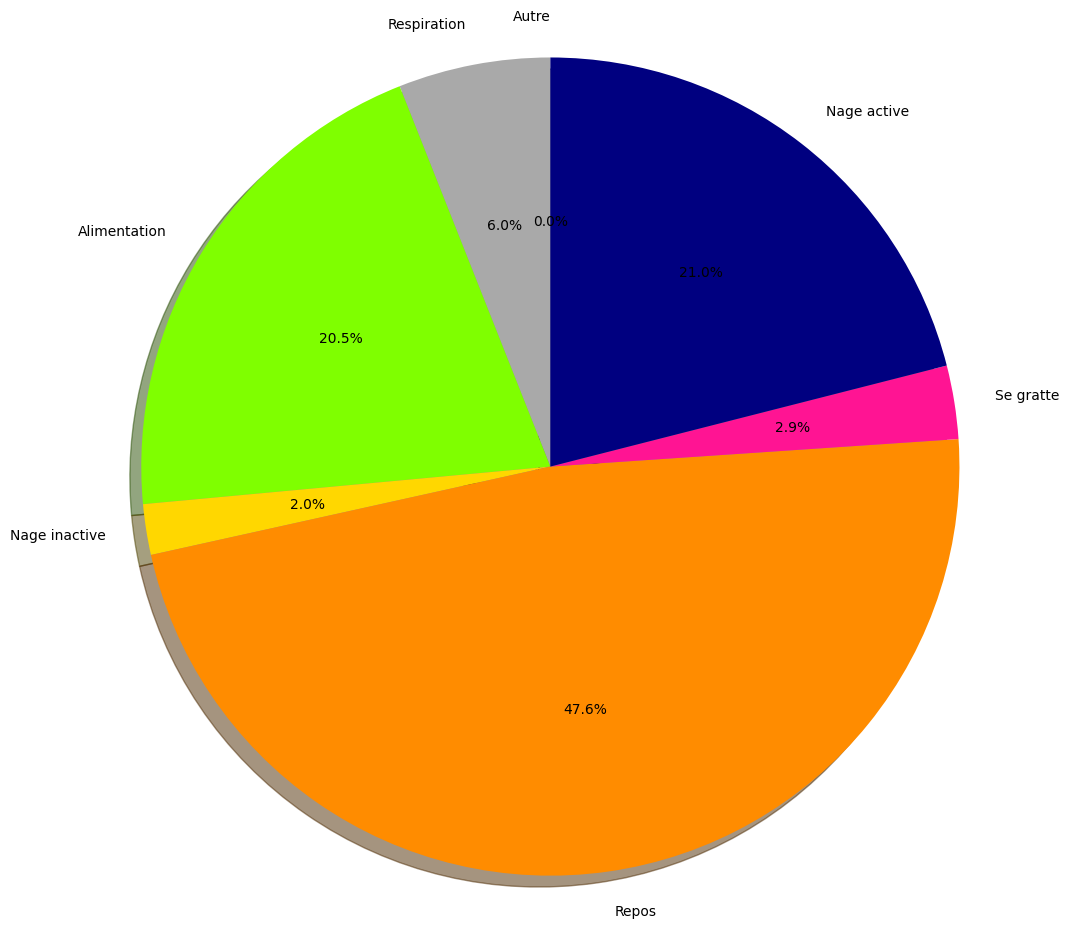

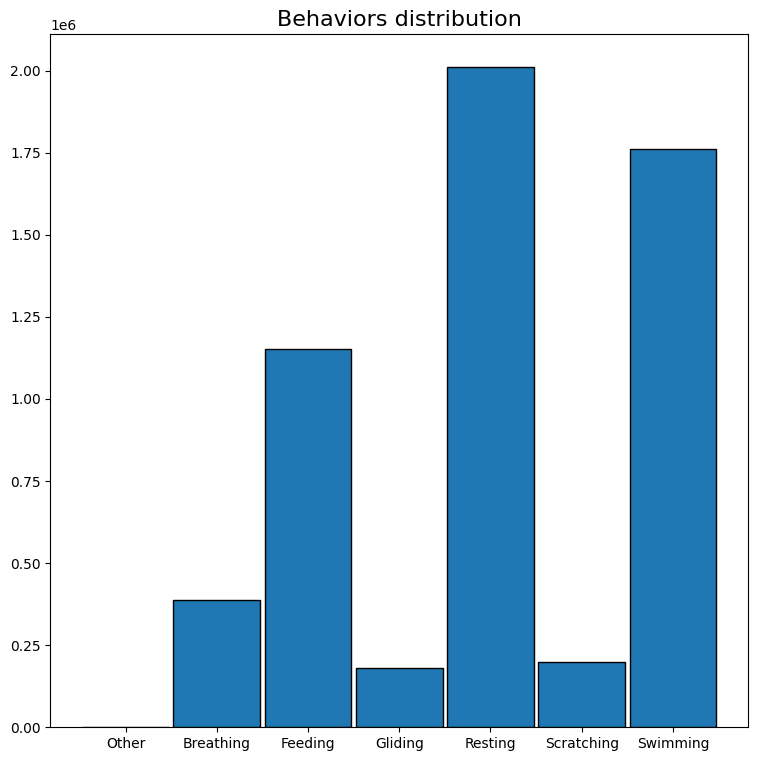

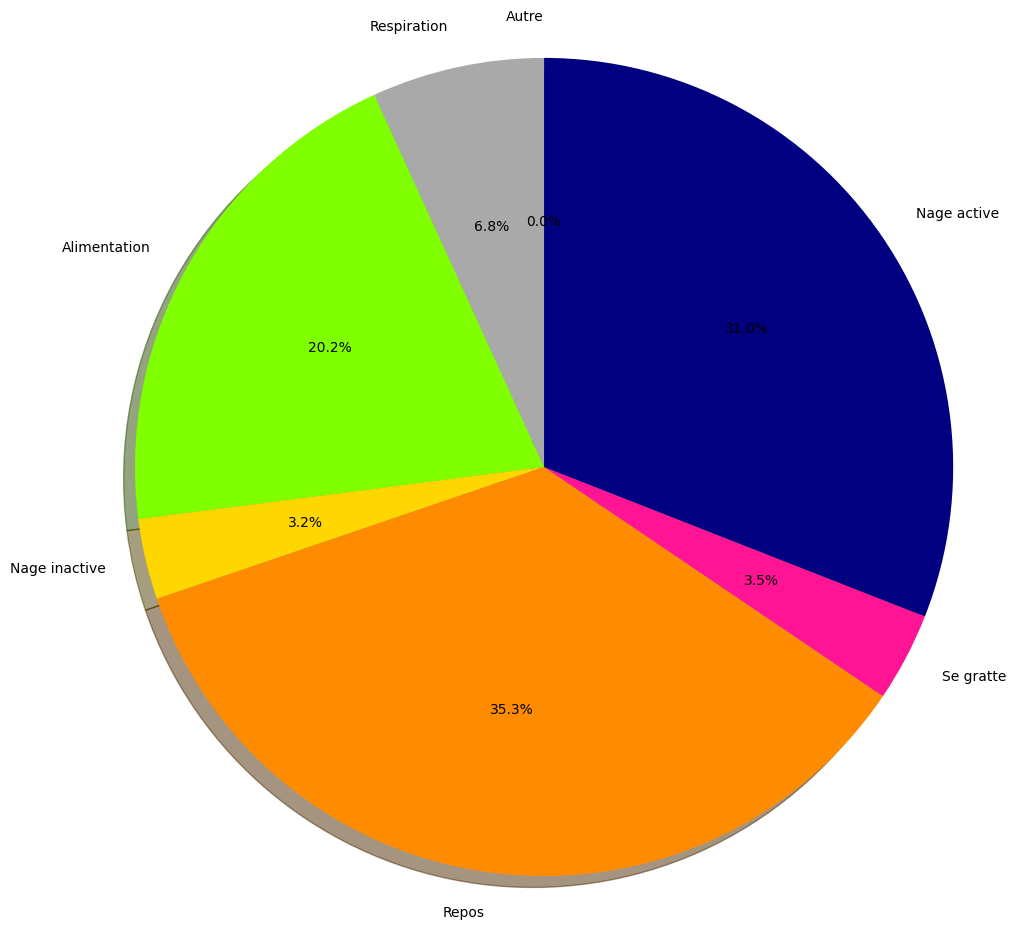

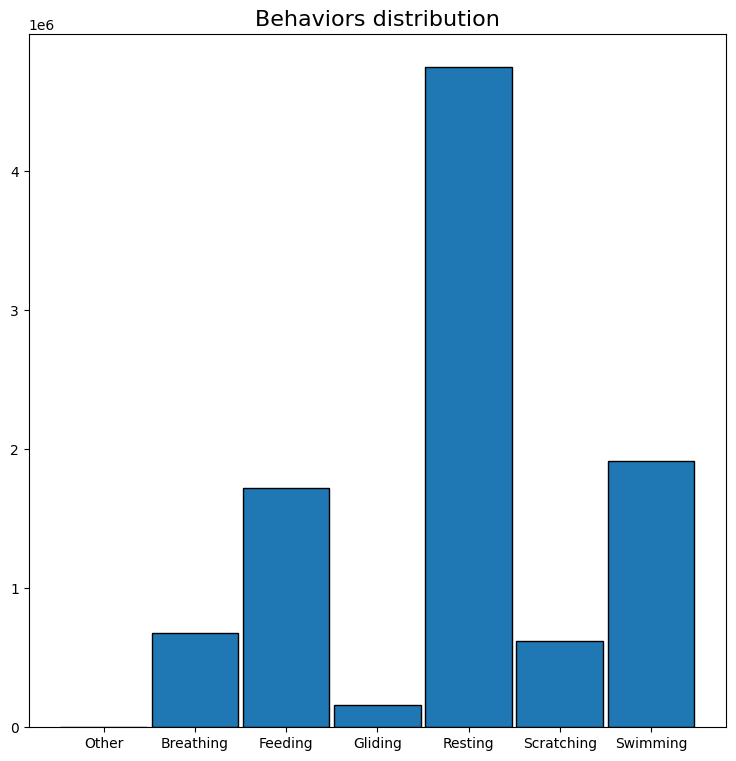

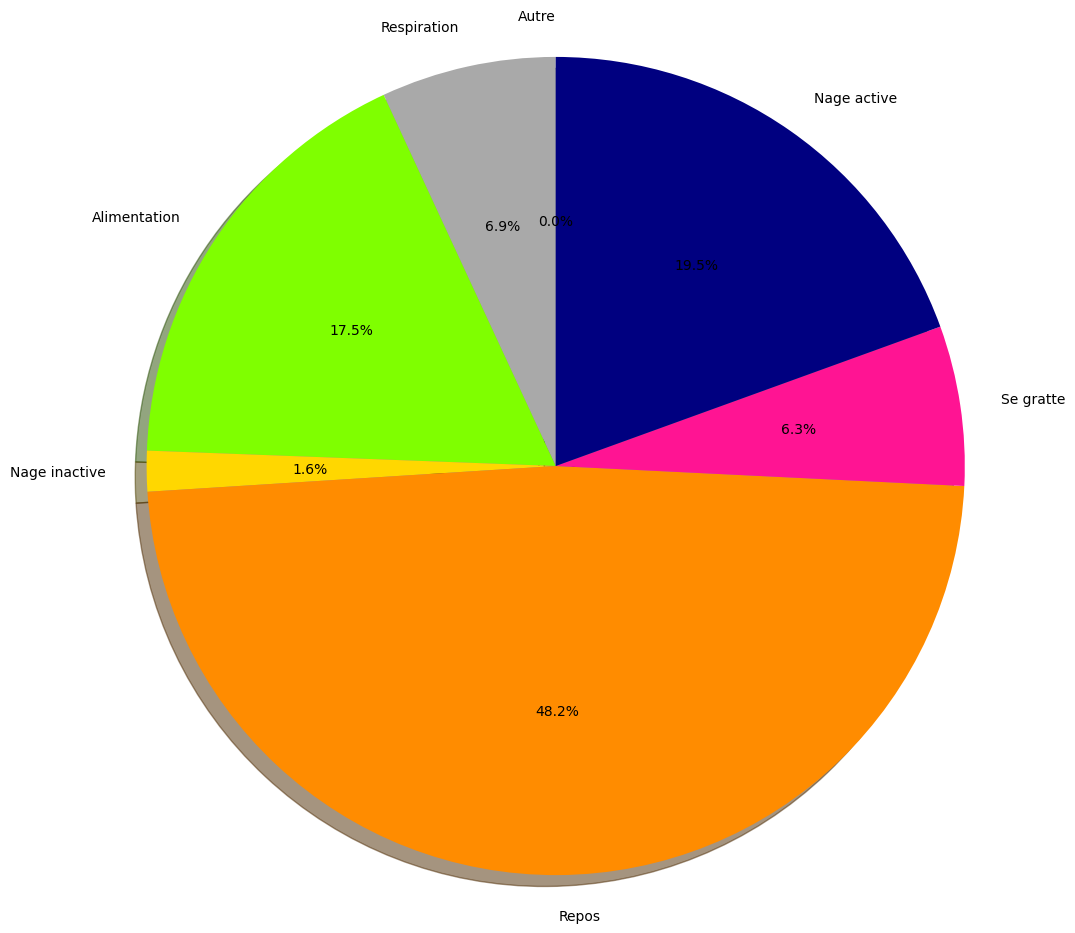

In [70]:
for TV in ALL_TV:
    if TV=='AGM1_TV_AN_08122020':
        KEPT_TIME_INTERVAL=("2020-12-08 10:03:56","2020-12-11 11:48:55")
        START=datetime.datetime.strptime("2020-12-08 09:29:16","%Y-%m-%d %H:%M:%S")  #cf excel Recap
    elif TV=='AGM2_TV_AN_08122020':
         KEPT_TIME_INTERVAL=("2020-12-08 10:11:45","2020-12-10 17:14:00") #AGM2_TV_AN_08122020
         START=datetime.datetime.strptime("2020-12-08 09:42:55","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM4_TV_AN_08122020':
        KEPT_TIME_INTERVAL=("2020-12-08 10:51:50","2020-12-11 11:21:30") #AGM2_TV_AN_08122020
        START=datetime.datetime.strptime("2020-12-08 10:14:31","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM1_TV_AN_15122020':
        KEPT_TIME_INTERVAL=("2020-12-15 11:37:14","2020-12-18 11:24:32")
        START=datetime.datetime.strptime("2020-12-15 09:46:07","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM2_TV_AN_15122020':
        KEPT_TIME_INTERVAL=("2020-12-15 11:18:27","2020-12-18 07:54:00")
        START=datetime.datetime.strptime("2020-12-15 09:14:48","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM1_TV_AN_19012021':
        KEPT_TIME_INTERVAL=("2021-01-19 11:19:06","2021-01-22 10:37:53")
        START=datetime.datetime.strptime("2021-01-19 08:50:02","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM2_TV_AN_19012021':
        KEPT_TIME_INTERVAL=("2021-01-19 11:30:00","2021-01-22 15:34:07")
        START=datetime.datetime.strptime("2021-01-19 08:57:24","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM4_TV_AN_19012021':
        KEPT_TIME_INTERVAL=("2021-01-19 11:01:56","2021-01-22 14:59:54")
        START=datetime.datetime.strptime("2021-01-19 09:03:43","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM1_TV_AN_29012021':
        KEPT_TIME_INTERVAL=("2021-01-29 12:07:58","2021-02-01 08:20:00")
        START=datetime.datetime.strptime("2021-01-28 17:50:19","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM2_TV_AN_29012021':
        KEPT_TIME_INTERVAL=("2021-01-29 11:55:00","2021-02-01 06:15:00")
        START=datetime.datetime.strptime("2021-01-28 17:51:05","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM4_TV_AN_29012021':
        KEPT_TIME_INTERVAL=("2021-01-29 12:16:40","2021-02-01 10:30:00")
        START=datetime.datetime.strptime("2021-01-28 17:51:38","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM1_TV_GA_23122020':
        KEPT_TIME_INTERVAL=("2020-12-23 12:01:00","2020-12-27 18:17:31")
        START=datetime.datetime.strptime("2020-12-23 07:30:26","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM2_TV_GA_23122020':
        KEPT_TIME_INTERVAL=("2020-12-23 11:24:08","2020-12-27 04:40:53")
        START=datetime.datetime.strptime("2020-12-23 07:27:01","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM4_TV_GA_23122020':
        KEPT_TIME_INTERVAL=("2020-12-23 11:42:11","2020-12-26 05:50:30")
        START=datetime.datetime.strptime("2020-12-23 07:28:50","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM5_TV_GA_22042021':
        KEPT_TIME_INTERVAL=("2021-04-22 12:05:00","2021-04-25 19:25:54")
        START=datetime.datetime.strptime("2021-04-22 04:08:38","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM1_TV_GA_30042021':
        KEPT_TIME_INTERVAL=("2021-04-30 12:48:00","2021-05-02 15:50:39")
        START=datetime.datetime.strptime("2021-04-30 10:24:30","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM4_TV_GA_30042021':
        KEPT_TIME_INTERVAL=("2021-04-30 11:17:45","2021-05-06 04:04:13")
        START=datetime.datetime.strptime("2021-04-30 09:25:00","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM5_TV_GA_30042021':
        KEPT_TIME_INTERVAL=("2021-04-30 11:45:02","2021-05-03 14:29:38")
        START=datetime.datetime.strptime("2021-04-30 09:52:24","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM1_TV_GA_07052021':
        KEPT_TIME_INTERVAL=("2021-05-07 11:46:27","2021-05-13 06:02:00")
        START=datetime.datetime.strptime("2021-05-07 04:35:33","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM6_TV_GA_07052021':
        KEPT_TIME_INTERVAL=("2021-05-07 11:55:00","2021-05-11 07:52:41")
        START=datetime.datetime.strptime("2021-05-07 04:36:25","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM1_TV_GA_25052021':
        KEPT_TIME_INTERVAL=("2021-05-25 10:36:00","2021-05-28 17:39:38")
        START=datetime.datetime.strptime("2021-05-24 15:24:09","%Y-%m-%d %H:%M:%S")
    elif TV=='AGM7_TV_AN_25052021':
        KEPT_TIME_INTERVAL=("2021-05-25 14:46:15","2021-05-30 10:27:00")
        START=datetime.datetime.strptime("2021-05-25 10:45:54","%Y-%m-%d %H:%M:%S")
        
##importation predictions
    print(TV)
    #DESCRIPTORS_SELEC=[0,1,2,3,4,5,9] 
    Y_stick_pred=np.load(PATH_Pred+'/'+TV+'=Y_pred.npy') 
    #Data=np.load(PATH_Data+'/'+TV+".npy")[:,DESCRIPTORS_SELEC]

    plot_histogramme(Y_stick_pred,TV)
    plot_budget_time(Y_stick_pred,TV)
    #plot_beh_accroding_time(Y_stick_pred, Data,TV,start=0, end=20000)
    creating_rblt_fichier(Y_stick_pred,TV,8,KEPT_TIME_INTERVAL,START)
